# 10 – Site Ranking

Turns the model's suitability scores into recommended locations for a new
bubble tea shop, using competition, business rules, and a field check.

**Method**
1. **Suitability:** spatial out-of-fold predictions from the logistic regression
   (each hexagon scored by a model that never saw its part of the city).
2. **Opportunity = suitability × 1 / (1 + competitors within 1 km).** A simplified
   Huff model: a new shop splits nearby demand evenly with existing competitors.
3. **Business rules:** at least the city-median number of residents aged 15–34
   nearby, and at least 3 food places inside the hexagon (a real commercial node).
4. **Commercial centers:** each site is placed at the median location of food
   places inside its hexagon, not the hexagon's geometric center.
5. **Spacing:** sites must be at least 1.5 km apart.
6. **Field check:** a top-10 shortlist was reviewed in Google Maps and Street View
   (`data/manual/site_checks.csv`), and the top 5 kept sites form the final list.

**Why the field check matters:** a first version without steps 3–4 recommended a
point in the Humber River (the hexagon's center fell in a park beside a commercial
strip) and an industrial area with few residents. Google Maps also showed
[X] competitors missing from OpenStreetMap across the shortlist.

**Final top 5**
| Rank | Area | Why |
|---|---|---|
| 1 | St. James Town | 43,000 young adults nearby; daily-needs retail; no bubble tea within 1 km |
| 2 | St. Clair West (Oakwood) | Busy commercial strip with 53 food places |
| 3 | Sheppard East (near Fairview Mall) | Strong food cluster in North York |
| 4 | Eglinton West (Little Jamaica) | On the new Line 5 Eglinton, so foot traffic should grow |
| 5 | Queen West (Parkdale/Roncesvalles) | High foot traffic and higher-income residents nearby |

**Limitations**
- The field check is a single reviewer's judgment, documented for transparency.
- The suitability model learns where shops *are*, not where they're *profitable*.

**Outputs:** `data/processed/top5_sites.gpkg`, `figures/top5_final.png`,
`figures/suitability_map.png`

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

P = "../data/processed/"
gdf = gpd.read_file(P + "scored_hexes.gpkg")
bubble = gpd.read_file(P + "bubble_tea.gpkg")
print("Hexagons:", len(gdf))

Hexagons: 846


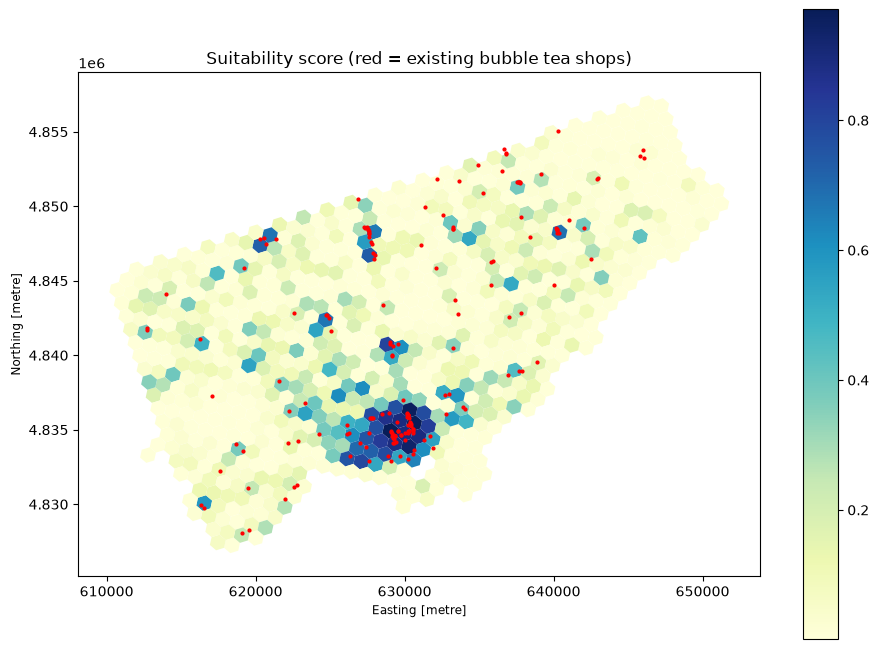

In [2]:
ax = gdf.plot(column="suitability", cmap="YlGnBu", legend=True, figsize=(11, 9))
bubble.plot(ax=ax, color="red", markersize=4)
ax.set_title("Suitability score (red = existing bubble tea shops)")
plt.savefig("../figures/suitability_map.png", dpi=150, bbox_inches="tight")

In [3]:
cand = gdf[gdf["has_bubble_tea"] == 0].copy()

# If a new shop split nearby demand evenly with existing competitors,
# it would get 1 / (1 + competitors) of it
cand["expected_share"] = 1 / (1 + cand["competitors_1km"])
cand["opportunity"] = cand["suitability"] * cand["expected_share"]

print("Candidate hexagons:", len(cand))
cand[["suitability", "competitors_1km", "opportunity"]].describe().round(3)

Candidate hexagons: 752


,suitability,competitors_1km,opportunity
count,752.000,752.000,752.000
mean,0.075,0.432,0.058
std,0.125,1.063,0.097
min,0.001,0.000,0.001
25%,0.006,0.000,0.006
50%,0.019,0.000,0.015
75%,0.094,0.000,0.066
max,0.830,12.000,0.778


In [4]:
def pick_sites(df, n=5, min_gap_m=1500):
    picks = []
    for _, row in df.sort_values("opportunity", ascending=False).iterrows():
        c = row.geometry.centroid
        if all(c.distance(p.geometry.centroid) >= min_gap_m for p in picks):
            picks.append(row)
        if len(picks) == n:
            break
    return gpd.GeoDataFrame(picks, crs=df.crs)

top5 = pick_sites(cand)

# Coordinates you can paste into Google Maps
pts = top5.geometry.centroid.to_crs(epsg=4326)
top5["lat"], top5["lon"] = pts.y.round(5), pts.x.round(5)

cols = ["suitability", "competitors_1km", "opportunity", "food_places_500m",
        "catchment_15_34", "median_hh_income", "dist_station_m", "lat", "lon"]
top5[cols].round(3).reset_index(drop=True)

,suitability,competitors_1km,opportunity,food_places_500m,catchment_15_34,median_hh_income,dist_station_m,lat,lon
0,0.778,0,0.778,47.0,43271.565,65099.459,721.982,43.667,-79.372
1,0.617,0,0.617,48.0,11224.055,92310.614,2003.569,43.678,-79.442
2,0.612,0,0.612,45.0,11162.209,84646.111,594.965,43.682,-79.422
3,0.548,0,0.548,25.0,7384.902,57596.301,2669.261,43.697,-79.516
4,0.543,0,0.543,36.0,4620.184,81593.344,1257.683,43.718,-79.460


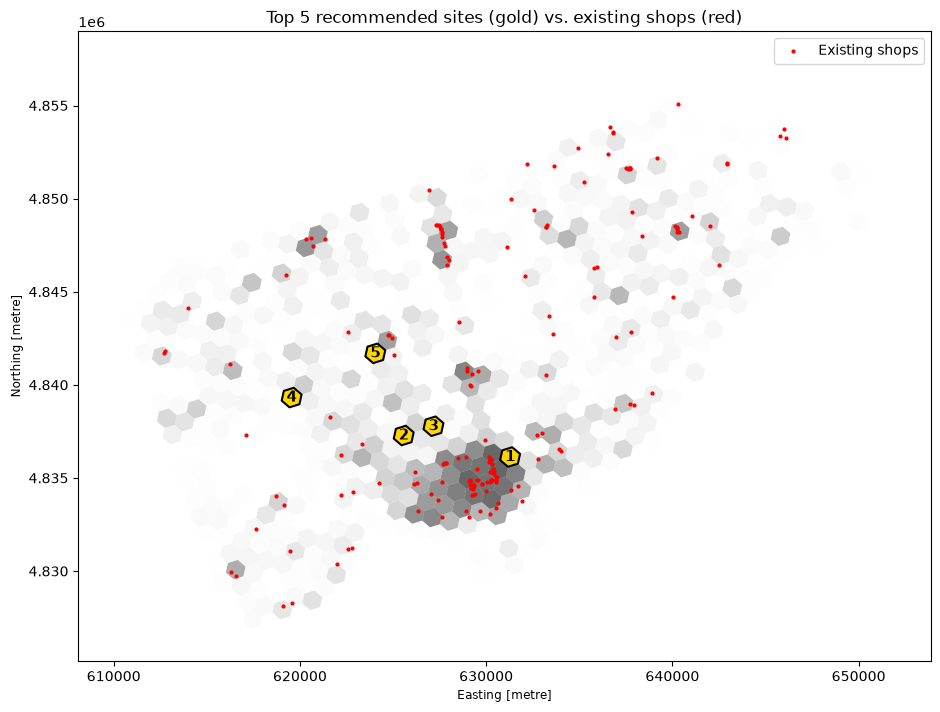

In [5]:
ax = gdf.plot(column="suitability", cmap="Greys", alpha=0.6, figsize=(11, 9))
bubble.plot(ax=ax, color="red", markersize=4, label="Existing shops")
top5.plot(ax=ax, color="gold", edgecolor="black", linewidth=1.5)
for i, (_, row) in enumerate(top5.iterrows(), start=1):
    c = row.geometry.centroid
    ax.annotate(str(i), (c.x, c.y), ha="center", va="center", fontsize=11, fontweight="bold")
ax.set_title("Top 5 recommended sites (gold) vs. existing shops (red)")
ax.legend()
plt.savefig("../figures/top5_sites.png", dpi=150, bbox_inches="tight")

In [6]:
food = gpd.read_file(P + "food_places.gpkg")

# Median location of food places inside each hexagon = its commercial center
food_in = gpd.sjoin(food, gdf[["h3_id", "geometry"]], predicate="within")
food_in["x"], food_in["y"] = food_in.geometry.x, food_in.geometry.y
hub = food_in.groupby("h3_id").agg(
    food_in_hex=("x", "size"), hub_x=("x", "median"), hub_y=("y", "median"))

cand2 = cand.merge(hub, left_on="h3_id", right_index=True, how="left")
cand2["food_in_hex"] = cand2["food_in_hex"].fillna(0)

MIN_YOUNG = gdf["catchment_15_34"].median()
eligible = cand2[(cand2["catchment_15_34"] >= MIN_YOUNG) & (cand2["food_in_hex"] >= 3)]

print(f"Rule: at least {MIN_YOUNG:,.0f} residents aged 15-34 nearby, and 3+ food places in the hexagon")
print("Candidates before rules:", len(cand2), "| after:", len(eligible))

Rule: at least 5,254 residents aged 15-34 nearby, and 3+ food places in the hexagon
Candidates before rules: 752 | after: 189


In [7]:
shortlist = pick_sites(eligible, n=10).reset_index(drop=True)

hub_pts = gpd.GeoSeries(
    gpd.points_from_xy(shortlist["hub_x"], shortlist["hub_y"]), crs=gdf.crs
).to_crs(epsg=4326)
shortlist["lat"], shortlist["lon"] = hub_pts.y.round(5).values, hub_pts.x.round(5).values
shortlist.index = shortlist.index + 1

shortlist[["opportunity", "suitability", "competitors_1km", "food_in_hex",
           "catchment_15_34", "median_hh_income", "lat", "lon"]].round(3)

,opportunity,suitability,competitors_1km,food_in_hex,catchment_15_34,median_hh_income,lat,lon
1,0.778,0.778,0,50.0,43271.565,65099.459,43.666,-79.369
2,0.617,0.617,0,53.0,11224.055,92310.614,43.678,-79.443
3,0.612,0.612,0,47.0,11162.209,84646.111,43.682,-79.422
4,0.548,0.548,0,25.0,7384.902,57596.301,43.700,-79.517
5,0.532,0.532,0,21.0,12701.937,74668.579,43.771,-79.332
6,0.482,0.482,0,27.0,10844.993,70436.593,43.696,-79.449
7,0.425,0.425,0,21.0,6174.617,59220.741,43.769,-79.187
8,0.378,0.378,0,37.0,9287.539,101041.718,43.640,-79.447
9,0.370,0.370,0,19.0,5852.190,75608.456,43.705,-79.477
10,0.360,0.360,0,26.0,13975.039,82798.671,43.665,-79.460


In [8]:
checks = pd.read_csv("../data/manual/site_checks.csv").set_index("rank")
final = shortlist.join(checks)

# How well did OpenStreetMap capture nearby competitors?
comp = final[["competitors_1km", "bubble_tea_within_1km"]].rename(
    columns={"competitors_1km": "OSM", "bubble_tea_within_1km": "Google Maps"})
missed = (comp["Google Maps"] - comp["OSM"]).clip(lower=0).sum()
print(f"Competitors found in Google Maps but missing from OSM: {missed} "
      f"(across {len(comp)} shortlisted sites)")
comp

Competitors found in Google Maps but missing from OSM: 2 (across 10 shortlisted sites)


,OSM,Google Maps
1,0,0
2,0,0
3,0,1
4,0,1
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0
10,0,0


In [9]:
top5 = final[final["verdict"] == "keep"].head(5).copy()
top5["final_rank"] = range(1, len(top5) + 1)
top5["geometry"] = gpd.points_from_xy(top5["hub_x"], top5["hub_y"])
top5 = gpd.GeoDataFrame(top5, geometry="geometry", crs=gdf.crs)

top5[["final_rank", "opportunity", "catchment_15_34", "food_in_hex",
      "median_hh_income", "lat", "lon", "notes"]].round(3)

,final_rank,opportunity,catchment_15_34,food_in_hex,median_hh_income,lat,lon,notes
1,1,0.778,43271.565,50.0,65099.459,43.666,-79.369,"Dense apartments; grocery store, pharmacy, cli..."
2,2,0.617,11224.055,53.0,92310.614,43.678,-79.443,"Busy commercial strip (fast food, banks, retai..."
5,3,0.532,12701.937,21.0,74668.579,43.771,-79.332,Many food businesses nearby; strongest of the ...
6,4,0.482,10844.993,27.0,70436.593,43.696,-79.449,A lot of food businesses nearby and medium foo...
8,5,0.378,9287.539,37.0,101041.718,43.640,-79.447,"high foot traffic, plus spending power nearby"


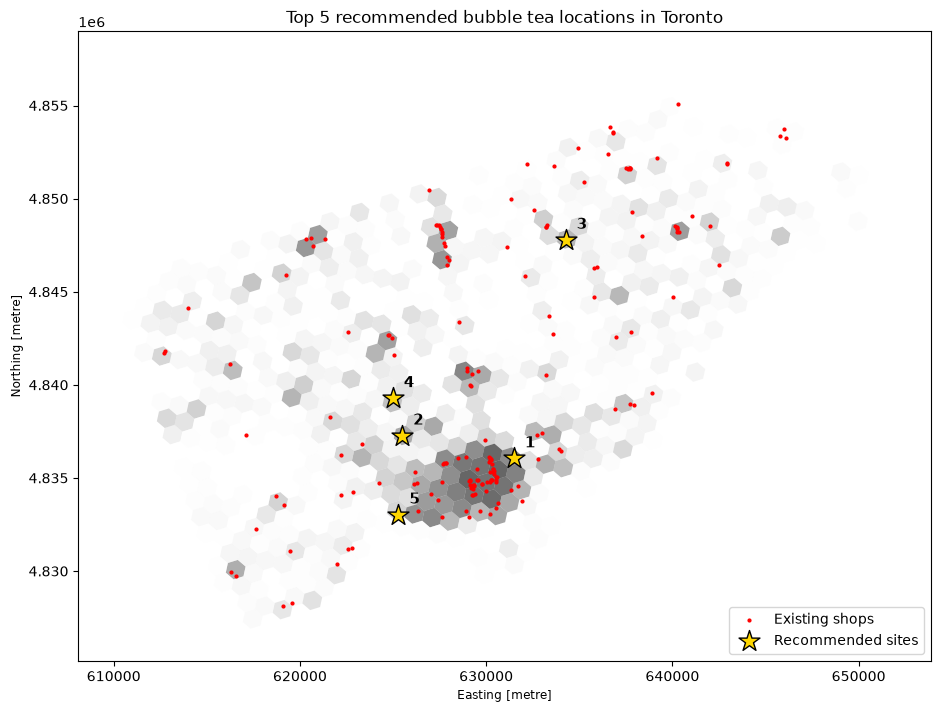

In [10]:
ax = gdf.plot(column="suitability", cmap="Greys", alpha=0.6, figsize=(11, 9))
bubble.plot(ax=ax, color="red", markersize=4, label="Existing shops")
top5.plot(ax=ax, color="gold", edgecolor="black", markersize=250, marker="*",
          label="Recommended sites")
for _, row in top5.iterrows():
    ax.annotate(str(row["final_rank"]), (row.geometry.x, row.geometry.y),
                xytext=(8, 8), textcoords="offset points", fontsize=11, fontweight="bold")
ax.set_title("Top 5 recommended bubble tea locations in Toronto")
ax.legend(loc="lower right")
plt.savefig("../figures/top5_final.png", dpi=150, bbox_inches="tight")

top5.drop(columns=["hub_x", "hub_y"]).to_file(P + "top5_sites.gpkg", driver="GPKG")